**Before running this notebook:**

1. Download the data: `uv run python -m ev_gap.download`
2. Run the data pipeline: `uv run python -m ev_gap.pipeline`. This notebook reads its output (`data/processed/districts.csv`).
3. Select the kernel of the `.venv` in this folder.

# Sensitivity check: do plug-in hybrids change the result?

The main model uses battery electric cars (BEV) as the car input. Plug-in hybrids (PHEV) can also charge at public charging points, so they may add demand. This notebook tests whether counting them changes the model, the errors or the ranking of underserved districts.

| Variant | Inputs of the linear model on logs | Car column of the baseline ratio |
|---|---|---|
| BEV only (the main model) | BEV, population, density | BEV |
| BEV and PHEV separate | BEV, PHEV, population, density | BEV |
| Plug-in cars combined | BEV + PHEV as one number, population, density | BEV + PHEV |

Same evaluation as before: 5-fold cross validation with random folds and with whole federal states held out. Every expected value comes from a model that did not see that district.

**What this can and cannot show.** It shows whether districts with more plug-in hybrids also have more charging points. It cannot show whether plug-in hybrid owners use public charging, because the data has no usage numbers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import GroupKFold

from ev_gap import config
from ev_gap.model import BASELINE, LINEAR, compare_feature_sets, make_models, random_folds, state_of
from ev_gap.pipeline import load_districts

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

districts = load_districts()
sets = config.FEATURE_SETS
print(len(districts), "districts")
print("plug-in hybrids:", f"{districts['phev'].sum():,}", "| BEV:", f"{districts['bev'].sum():,}",
      "| share of plug-in hybrids among plug-in cars:", f"{districts['phev'].sum() / districts['plugin_cars'].sum():.0%}")

399 districts
plug-in hybrids: 1,121,516 | BEV: 2,031,870 | share of plug-in hybrids among plug-in cars: 36%


## 1. How different are BEV and PHEV across districts?

If every district had the same mix of BEV and PHEV, the two would carry the same information and the check could not change anything. The mix is shown below.

PHEV share of plug-in cars per district: 10th percentile 29% | median 35% | 90th percentile 42%
correlation of log(BEV) and log(PHEV): 0.96
correlation of log(PHEV) and log(population): 0.94


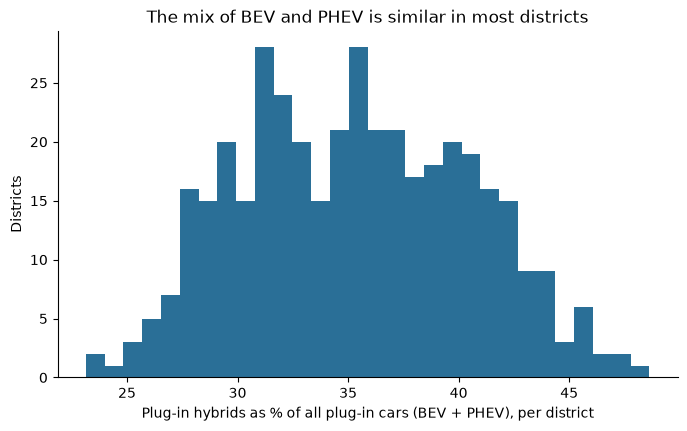

In [2]:
phev_share = districts["phev"] / districts["plugin_cars"]
print("PHEV share of plug-in cars per district: 10th percentile", f"{phev_share.quantile(.1):.0%}",
      "| median", f"{phev_share.median():.0%}", "| 90th percentile", f"{phev_share.quantile(.9):.0%}")
print("correlation of log(BEV) and log(PHEV):", round(np.log(districts["bev"]).corr(np.log(districts["phev"])), 2))
print("correlation of log(PHEV) and log(population):", round(np.log(districts["phev"]).corr(np.log(districts["population"])), 2))

fig, ax = plt.subplots()
ax.hist(phev_share * 100, bins=30, color="#2a6f97")
ax.set_xlabel("Plug-in hybrids as % of all plug-in cars (BEV + PHEV), per district")
ax.set_ylabel("Districts")
ax.set_title("The mix of BEV and PHEV is similar in most districts")
plt.show()

## 2. Does the prediction get better?

Typical error is the median of |expected minus actual| divided by actual, as in the model notebook. Lower is better.

In [3]:
random_expected, random_scores = compare_feature_sets(districts, sets, random_folds())
state_expected, state_scores = compare_feature_sets(districts, sets, GroupKFold(n_splits=5), groups=state_of(districts))

def typical_error(scores):
    table = scores.groupby(["feature_set", "model"])["median_error_pct"].mean().unstack("model")
    return table.reindex(list(sets))[[BASELINE, LINEAR]].round(1)

print("Typical error in %, random folds")
print(typical_error(random_scores).to_string())
print()
print("Typical error in %, folds by federal state")
print(typical_error(state_scores).to_string())

Typical error in %, random folds
model                  Baseline ratio  Linear regression on logs
feature_set                                                     
BEV only                         26.6                       21.1
BEV and PHEV separate            26.6                       21.7
Plug-in cars combined            25.0                       21.3

Typical error in %, folds by federal state
model                  Baseline ratio  Linear regression on logs
feature_set                                                     
BEV only                         28.2                       22.9
BEV and PHEV separate            28.2                       22.2
Plug-in cars combined            26.3                       23.4


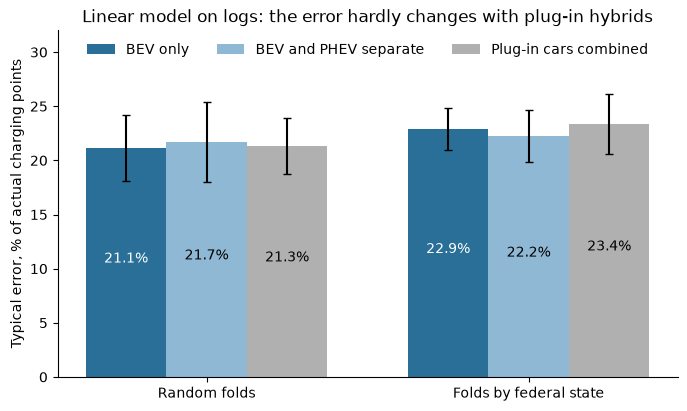

In [4]:
fig, ax = plt.subplots()
width = 0.25
colors = ["#2a6f97", "#8fb8d4", "#b0b0b0"]
for i, name in enumerate(sets):
    values, errors = [], []
    for scores in (random_scores, state_scores):
        part = scores[(scores["feature_set"] == name) & (scores["model"] == LINEAR)]["median_error_pct"]
        values.append(part.mean())
        errors.append(part.std())
    positions = np.arange(2) + (i - 1) * width
    ax.bar(positions, values, width, yerr=errors, capsize=3, color=colors[i], label=name)
    for x, v in zip(positions, values):
        ax.text(x, v / 2, f"{v:.1f}%", ha="center", color="white" if i == 0 else "black")
ax.set_xticks(range(2), ["Random folds", "Folds by federal state"])
ax.set_ylabel("Typical error, % of actual charging points")
ax.set_title("Linear model on logs: the error hardly changes with plug-in hybrids")
ax.set_ylim(0, 32)
ax.legend(frameon=False, loc="upper center", ncol=3)
plt.show()

In [5]:
# Is any difference larger than the random variation between splits? Repeat with 10 different splits.
rows = []
for seed in range(10):
    _, repeat = compare_feature_sets(districts, sets, random_folds(seed=seed))
    rows.append(repeat[repeat["model"] == LINEAR].groupby("feature_set")["median_error_pct"].mean())
repeats = pd.DataFrame(rows).reset_index(drop=True).reindex(columns=list(sets))
print("Typical error of the linear model in 10 random splits, %")
print(repeats.describe().loc[["mean", "min", "max"]].round(2).to_string())
print()
differences = pd.DataFrame({
    "BEV only minus BEV and PHEV separate": repeats["BEV only"] - repeats["BEV and PHEV separate"],
    "BEV only minus Plug-in cars combined": repeats["BEV only"] - repeats["Plug-in cars combined"],
})
print("Difference per split, in percentage points (positive: the variant with plug-in hybrids is better)")
print(differences.round(2).T.to_string())
print("splits (of 10) where the variant with plug-in hybrids is better than BEV only:", (differences > 0).sum().tolist())
print("average difference in percentage points:", differences.mean().round(2).tolist())

Typical error of the linear model in 10 random splits, %
feature_set  BEV only  BEV and PHEV separate  Plug-in cars combined
mean            20.61                  20.71                  20.77
min             20.22                  20.32                  20.39
max             20.97                  21.15                  21.64

Difference per split, in percentage points (positive: the variant with plug-in hybrids is better)
                                         0     1     2     3     4     5     6     7     8     9
BEV only minus BEV and PHEV separate -0.03 -0.30 -0.03 -0.50 -0.32 -0.05  0.42  0.03 -0.12 -0.10
BEV only minus Plug-in cars combined -0.06 -0.13  0.21 -0.01  0.25 -0.39 -0.79 -0.41 -0.04 -0.27
splits (of 10) where the variant with plug-in hybrids is better than BEV only: [2, 2]
average difference in percentage points: [-0.1, -0.16]


**What the comparison shows**

- The three variants of the linear model have about the same typical error: about 21% to 22% with random folds and 22% to 23% with folds by state. Differences are below 1 percentage point, and the sign changes between the two evaluations. The 10 repeated splits give 20.6% for BEV only, 20.7% for BEV and PHEV separate and 20.8% for plug-in cars combined.
- Counting plug-in hybrids does not make the model better. If anything it is very slightly worse: the variants with plug-in hybrids are better than BEV only in only 2 of 10 splits each, and worse by 0.1 to 0.2 percentage points on average.
- The simple baseline ratio does improve a little when it counts plug-in cars instead of BEV (26.6% to 25.0% with random folds, 28.2% to 26.3% by state). Plug-in cars also follow the number of residents closely (correlation of the logs 0.94), so this is probably a better stand-in for district size, not a sign of extra charging demand. This was not tested.
- The mix of BEV and PHEV is similar in most districts: PHEV are 29% to 42% of plug-in cars in 80% of the districts. This is why adding them changes little.

## 3. Do the coefficients tell how much plug-in hybrids matter?

Elasticities of the linear model, fitted on all districts. If the input is 10% higher, the expected charging points are about (coefficient x 10)% higher.

In [6]:
rows = {}
for name, spec in sets.items():
    model = make_models(car_column=spec["car_column"])[LINEAR].fit(districts[spec["features"]], districts[config.TARGET])
    rows[name] = pd.Series(model.regressor_.steps[-1][1].coef_, index=spec["features"])
print(pd.DataFrame(rows).round(2).to_string(na_rep=""))

             BEV only  BEV and PHEV separate  Plug-in cars combined
bev              0.48                   0.54                       
density          0.07                   0.08                   0.06
phev                                   -0.11                       
plugin_cars                                                    0.54
population       0.45                   0.50                   0.38


In the variant with BEV and PHEV separate, the PHEV coefficient is small and negative (-0.11), and the BEV coefficient rises from 0.48 to 0.54. This should not be read as "plug-in hybrids reduce charging points". BEV and PHEV are very strongly correlated across districts (0.96 for the logs), so the model cannot separate their effects. The coefficients of the two are unstable. The honest reading is: given BEV, PHEV adds no useful information about the number of charging points.

## 4. Does the ranking of underserved districts change?

Gap in percent = (actual minus expected) / expected, from the linear model, out of fold. The comparison uses the rank correlation (1 means the same order) and the overlap of the most underserved districts.

                       rank correlation with BEV only  same districts in the 20 most underserved  same districts in the 55 most underserved  districts more than 30% below expected
variant                                                                                                                                                                            
BEV and PHEV separate                           0.998                                         20                                         53                                      53
Plug-in cars combined                           0.996                                         18                                         52                                      56
BEV only: districts more than 30% below expected: 55


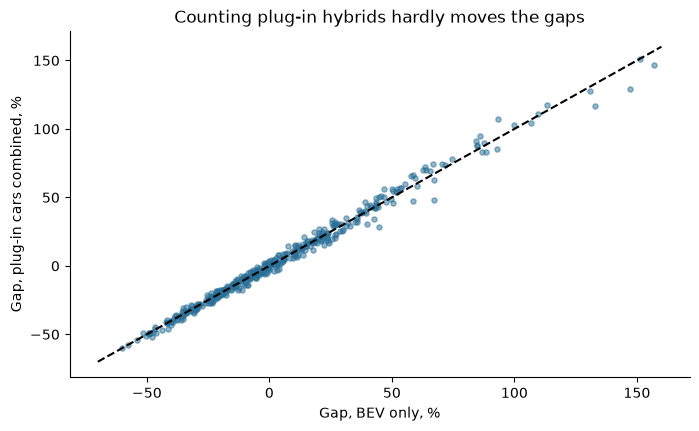

In [7]:
def gap_pct(expected_tables, name):
    expected = expected_tables[name][LINEAR]
    return (districts[config.TARGET] - expected) / expected * 100

gaps = pd.DataFrame({name: gap_pct(random_expected, name) for name in sets})
reference = gaps["BEV only"]
rows = []
for name in list(sets)[1:]:
    rows.append({
        "variant": name,
        "rank correlation with BEV only": round(reference.rank().corr(gaps[name].rank()), 3),
        "same districts in the 20 most underserved": len(set(reference.nsmallest(20).index) & set(gaps[name].nsmallest(20).index)),
        "same districts in the 55 most underserved": len(set(reference.nsmallest(55).index) & set(gaps[name].nsmallest(55).index)),
        "districts more than 30% below expected": int((gaps[name] < -30).sum()),
    })
print(pd.DataFrame(rows).set_index("variant").to_string())
print("BEV only: districts more than 30% below expected:", int((reference < -30).sum()))

fig, ax = plt.subplots()
ax.scatter(reference, gaps["Plug-in cars combined"], s=14, alpha=0.5, color="#2a6f97")
ax.plot([-70, 160], [-70, 160], color="black", linestyle="--")
ax.set_xlabel("Gap, BEV only, %")
ax.set_ylabel("Gap, plug-in cars combined, %")
ax.set_title("Counting plug-in hybrids hardly moves the gaps")
plt.show()

In [8]:
changes = (gaps["Plug-in cars combined"] - reference)
movers = changes.abs().nlargest(8).index
table = pd.DataFrame({
    "district": districts.loc[movers, "name"],
    "BEV": districts.loc[movers, "bev"],
    "PHEV": districts.loc[movers, "phev"],
    "PHEV share of plug-in cars": (districts.loc[movers, "phev"] / districts.loc[movers, "plugin_cars"]).round(2),
    "gap BEV only, %": reference[movers].round(0),
    "gap plug-in cars, %": gaps.loc[movers, "Plug-in cars combined"].round(0),
})
print("The 8 districts whose gap changes most")
print(table.to_string(index=False))

The 8 districts whose gap changes most
                   district   BEV  PHEV  PHEV share of plug-in cars  gap BEV only, %  gap plug-in cars, %
           Wolfsburg, Stadt 15832 10178                        0.39             67.0                 48.0
                 Ingolstadt 10294  6390                        0.38            147.0                129.0
      Stuttgart, Stadtkreis 21837 17016                        0.44            133.0                116.0
                Schweinfurt  1293  1224                        0.49             45.0                 28.0
               Emden, Stadt   874   369                        0.30             93.0                107.0
                  Böblingen 18590 12867                        0.41             58.0                 47.0
      Heilbronn, Stadtkreis  2420  1852                        0.43            157.0                146.0
Mecklenburgische Seenplatte  2444  2046                        0.46             40.0                 31.0


**What the ranking shows**

- The ranking is almost the same in every variant. The rank correlation with the main model is 0.998 (BEV and PHEV separate) and 0.996 (plug-in cars combined).
- In the plug-in cars variant, 18 of the 20 most underserved districts and 52 of the 55 most underserved districts are the same as with BEV only. With BEV and PHEV separate it is 20 of 20 and 53 of 55.
- The districts that move most are well supplied ones (Wolfsburg, Stuttgart, Ingolstadt), and most of them have a higher share of plug-in hybrids than the median of 35% (up to 49%). They stay far above their expected value.

## 5. Conclusion

- Including plug-in hybrids does not change the result. The prediction error stays about the same, and the list of underserved districts is nearly identical.
- The reason is visible in the data: districts have a similar mix of BEV and PHEV (the PHEV share of plug-in cars is between 29% and 42% in 80% of districts), and the two counts are strongly correlated. They carry almost the same information.
- For a business that sells plug-in hybrids or battery electric cars, the underserved districts are the same either way, so the main result is robust to this choice. We keep BEV as the main input.
- **Limit.** The check shows that districts with more plug-in hybrids have about as many charging points as BEV counts would suggest. It does not show whether plug-in hybrid owners use public charging. Home and workplace charging is not in the data.